# 04. 양자화 품질 측정 — KL Divergence vs Disk Size

양자화 방식들 중 sweet spot이 있다면 어디인지 **직접 측정**합니다.

**측정 대상**: Qwen3.5-4B GGUF 모델의 여러 양자화 variant

**방법**:
1. 같은 prompt들에 대해 각 변환 모델의 next-token 확률 분포를 구함
2. **Q8_0**을 baseline (사실상 fp16과 비슷)으로 두고, 다른 변환들과의 KL Divergence를 계산
3. KLD ↑ = baseline에서 멀어짐 = 양자화 품질 ↓
4. KLD vs disk size plot으로 sweet spot 시각화

**TODO는 마지막에 하나만 있습니다**.

> llama-server HTTP API (`/completion` + `n_probs`)를 사용하여 top-N 확률 분포를 수집하고,
> 근사 KLD를 계산합니다. 각 variant마다 서버를 재기동합니다.

**실습 환경 (A4000 16GB)**: 측정용 서버는 **포트 8090 / Windows 로컬 프로세스** 로 뜨므로, 03번에서 띄운 공용 서버(:8080)는 켜둔 채로 진행해도 됩니다.

> 모델 파일은 공개 GGUF 저장소에서 받습니다. Unsloth 학습 라이브러리는 사용하지 않습니다.


## 🧭 시작 전에

> **50분 핵심 경로**: Q8_0 기준 모델과 Q4_K_M·Q3_K_M을 같은 3개 프롬프트로 측정하고, KL divergence와 파일 크기를 비교합니다. 추가 quant는 선택입니다.

| 항목 | 내용 |
|---|---|
| 🎯 학습 목표 | 양자화가 무엇인지 이해하고, 비트 수를 줄일 때 품질이 얼마나 떨어지는지 직접 측정해 내 환경에 맞는 양자화를 고르는 기준을 세운다 |
| 📚 사전 지식 | 00번 3절(VRAM 계산), 01번(다음 토큰 확률분포), 03번(llama-server) |
| 🐍 커널(환경) | `LLM Hands-On (Win CUDA)` |
| 🖥️ GPU 사용 | 측정용 서버 4B ≈ 5 GB (포트 8090, 공용 서버와 동시 실행 가능) |
| ⏱️ 소요 시간 | 약 30~40분 (변형 4개 다운로드 약 13GB 포함) |
| 서버 | Windows llama-server 프로세스 (포트 8090) |

> **실행 요령**: 위에서부터 **한 셀씩**(Shift+Enter) 실행하세요. `Run All`은 쓰지 마세요.
> `✅ TODO 셀`은 학생이 채우는 칸이라 그대로 실행하면 일부러 에러가 납니다. 막히면 바로 아래 `✅ 참고 답안` 셀을 보세요.

## 📖 핵심 개념: 양자화와 KL Divergence

**양자화 = 숫자 반올림 압축**
```
원본(bf16):   0.123456789  → 16bit
Q8_0  (8bit): 0.1235       → 메모리 약 1/2, 거의 차이 없음
Q4_K_M(4bit): 0.12         → 메모리 약 1/3.3, 약간의 차이
Q2_K  (2~3bit): 0.1        → 메모리 약 1/5, 품질 크게 저하
```

| 이름 | 대략 비트/파라미터 | 4B 파일 크기 | 한 줄 평 |
|---|---|---|---|
| Q8_0 | ≈ 8.5 | ≈ 4.5 GB | 원본과 거의 같음 (이번 실험의 기준) |
| Q5_K_M | ≈ 5.7 | ≈ 3.2 GB | 안전한 선택 |
| Q4_K_M | ≈ 4.8 | ≈ 2.7 GB | 가장 많이 쓰는 균형점 |
| Q3_K_M | ≈ 3.9 | ≈ 2.2 GB | 품질 저하 시작 |
| Q2_K | ≈ 3 | ≈ 1.8 GB | 비상용 |

(`K`는 llama.cpp의 개선된 양자화 방식, `_M`/`_S`는 중요 층을 얼마나 더 정밀하게 남기는지를 뜻합니다)

**어떻게 품질을 잴까? → KL Divergence**
같은 문장을 주고 두 모델이 만든 **다음 토큰 확률분포**를 비교합니다 (01번에서 본 그 분포).
```
기준(Q8_0):  " 서울" 0.90  " 세종" 0.05  ...
비교(Q3_K_M): " 서울" 0.80  " 세종" 0.12  ...
KL divergence = 두 분포가 얼마나 다른지 (0이면 완전히 같음, 클수록 원본에서 멀어짐)
```

## 0. 환경 준비

llama-server는 이 폴더의 `local_server.py`로 기동합니다. 모델 파일(호스트 경로)만 인자로 넘기면,
Windows 로컬 llama-server가 모델 파일을 직접 열고 `localhost:8090`에서 제공합니다.


In [10]:
import os, glob, time, json, gc
import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from local_llm import preset_model_dir

MODEL_DIR = preset_model_dir('4b')
os.makedirs(MODEL_DIR, exist_ok=True)
REPO = 'unsloth/Qwen3.5-4B-GGUF'
SERVER_PORT = 8090
BASE_URL = f'http://127.0.0.1:{SERVER_PORT}'
N_PROBS = 128
print('Environment ready; using the bundled Windows server')

Environment ready; using the bundled Windows server


## 1. Preloaded GGUF variants

`setup_environment.bat` downloads the three variants used in the core experiment.

- `Q8_0` — reference distribution
- `Q4_K_M` — medium compression
- `Q3_K_M` — higher compression


In [11]:
VARIANTS = ['Q8_0', 'Q4_K_M', 'Q3_K_M']

# 셋업이 모든 quant 파일을 미리 받습니다. 이 셀은 로컬 파일만 확인합니다.
# 어떤 파일이 받아졌는지 확인
files = sorted(glob.glob(f'{MODEL_DIR}/**/*.gguf', recursive=True))
missing = [v for v in VARIANTS if not any(v in os.path.basename(p) for p in files)]
if missing:
    raise RuntimeError('Course GGUF files are missing; rerun setup_environment.bat: ' + ', '.join(missing))
for p in files:
    sz = os.path.getsize(p) / (1024**3)
    print(f'  {sz:5.2f} GB  {os.path.basename(p)}')

   2.14 GB  Qwen3.5-4B-Q3_K_M.gguf
   2.55 GB  Qwen3.5-4B-Q4_K_M.gguf
   4.17 GB  Qwen3.5-4B-Q8_0.gguf
   0.63 GB  mmproj-F16.gguf


In [12]:
# variant 이름 → 파일 경로 매핑
def find_path(variant: str) -> str:
    matches = [p for p in files if variant in os.path.basename(p)
               and 'mmproj' not in os.path.basename(p).lower()]
    if not matches:
        raise RuntimeError(f'{variant} GGUF 파일을 찾을 수 없음')
    return matches[0]

VARIANT_PATHS = {v: find_path(v) for v in VARIANTS}
for v, p in VARIANT_PATHS.items():
    print(f'{v:8s} → {p}')

Q8_0     → d:\유연휘\LLM_Research_Lab_Student\models\Qwen3.5-4B-GGUF\Qwen3.5-4B-Q8_0.gguf
Q4_K_M   → d:\유연휘\LLM_Research_Lab_Student\models\Qwen3.5-4B-GGUF\Qwen3.5-4B-Q4_K_M.gguf
Q3_K_M   → d:\유연휘\LLM_Research_Lab_Student\models\Qwen3.5-4B-GGUF\Qwen3.5-4B-Q3_K_M.gguf


## 2. Evaluation prompts

The core experiment uses three short prompts in Korean and English.


In [13]:
EVAL_PROMPTS = [
    '한국의 수도는',
    'The capital of France is',
    '광합성은 식물이',
]
print(f'평가 prompt {len(EVAL_PROMPTS)}개 준비 완료')


평가 prompt 3개 준비 완료


## 3. 서버 관리 + KLD 계산 함수

**핵심 로직**:

1. Python 함수로 variant별 Windows llama-server 프로세스를 기동
2. `/completion` endpoint에 `n_probs=128`로 요청하여 top-128 확률 분포 수집
3. 두 분포 (baseline P vs quantized Q) 사이 $D_{KL}(P \| Q) = \sum_x P(x) \log \frac{P(x)}{Q(x)}$
4. top-N 밖의 토큰은 잔여 확률을 균등 배분하여 근사

In [14]:
# Windows 로컬 서버의 시작과 종료

def start_server(model_path: str, timeout: int = 120):
    from local_server import start_server as start_local
    pid = start_local(model_path, port=SERVER_PORT, ctx_size=2048,
                      n_predict=1, jinja=False, timeout=timeout)
    _update_vocab_size()
    for attempt in range(5):
        try:
            requests.post(f'{BASE_URL}/completion',
                          json={'prompt': 'hi', 'n_predict': 1, 'n_probs': 1},
                          timeout=120)
            print(f'  warm-up complete (pid={pid})')
            return
        except Exception:
            time.sleep(3)
    print('  warm-up failed; continuing')

def stop_server():
    from local_server import stop_server as stop_local
    stop_local(SERVER_PORT)
    time.sleep(2)

def get_next_token_logprobs(prompt: str, max_retries: int = 3) -> dict:
    for attempt in range(max_retries):
        try:
            resp = requests.post(f'{BASE_URL}/completion', json={
                'prompt': prompt, 'n_predict': 1, 'n_probs': N_PROBS,
                'temperature': 1.0,
            }, timeout=120)
            resp.raise_for_status()
            data = resp.json()
            cp = data.get('completion_probabilities', [])
            if cp and 'top_logprobs' in cp[0]:
                return {item['id']: item['logprob'] for item in cp[0]['top_logprobs']}
        except Exception:
            if attempt == max_retries - 1:
                raise
            time.sleep(5)
    raise RuntimeError('Could not obtain completion probabilities')

def collect_all_prompts() -> list:
    dists = []
    for i, prompt in enumerate(EVAL_PROMPTS):
        dists.append(get_next_token_logprobs(prompt))
        if (i + 1) % 5 == 0:
            print(f'  {i+1}/{len(EVAL_PROMPTS)} complete')
    return dists

VOCAB_SIZE = 151936

def _update_vocab_size():
    global VOCAB_SIZE
    try:
        meta = requests.get(f'{BASE_URL}/v1/models', timeout=5).json()['data'][0].get('meta', {})
        if meta.get('n_vocab'):
            VOCAB_SIZE = int(meta['n_vocab'])
    except Exception:
        pass

def kld(p_logprobs: dict, q_logprobs: dict) -> float:
    p_probs = {k: np.exp(v) for k, v in p_logprobs.items()}
    q_probs = {k: np.exp(v) for k, v in q_logprobs.items()}
    q_top_sum = sum(q_probs.values())
    q_floor = max(1.0 - q_top_sum, 1e-30) / max(VOCAB_SIZE - len(q_probs), 1)
    val = 0.0
    for tok, p in p_probs.items():
        if p <= 0:
            continue
        q = q_probs.get(tok, q_floor)
        val += p * (np.log(p) - np.log(max(q, 1e-30)))
    return max(val, 0.0)

print('KLD server functions ready')


KLD server functions ready


## 4. Baseline 분포 계산 (Q8_0)

Q8_0를 "정답"으로 삼고, 다른 quant들이 여기서 얼마나 벗어나는지 측정.

In [15]:
print('Q8_0 baseline 서버 기동...')
start_server(VARIANT_PATHS['Q8_0'])

print('20개 prompt에 대해 baseline 분포 수집...')
t0 = time.time()
baseline_dists = collect_all_prompts()
print(f'전체 소요: {time.time() - t0:.1f}s')

stop_server()
print('baseline 서버 종료')

Q8_0 baseline 서버 기동...
llama-server ready on http://127.0.0.1:8090 (pid=21088)
  warm-up complete (pid=21088)
20개 prompt에 대해 baseline 분포 수집...
전체 소요: 0.2s
llama-server stopped on port 8090
baseline 서버 종료


## 5. 각 quant variant의 KLD 측정

In [16]:
results = []

for variant in VARIANTS:
    path = VARIANT_PATHS[variant]
    size_gb = os.path.getsize(path) / (1024**3)
    print(f'\n--- {variant} ({size_gb:.2f} GB) ---')

    if variant == 'Q8_0':
        results.append({'variant': variant, 'size_gb': size_gb,
                        'mean_kld': 0.0, 'max_kld': 0.0})
        print('  baseline → KLD = 0.0 (skip)')
        continue

    start_server(path)
    t0 = time.time()
    quant_dists = collect_all_prompts()
    print(f'  수집 완료 ({time.time() - t0:.1f}s)')
    stop_server()

    klds = [kld(baseline_dists[i], quant_dists[i])
            for i in range(len(EVAL_PROMPTS))]
    mean_kld = float(np.mean(klds))
    max_kld = float(np.max(klds))
    results.append({'variant': variant, 'size_gb': size_gb,
                    'mean_kld': mean_kld, 'max_kld': max_kld})
    print(f'  mean KLD = {mean_kld:.6f}, max = {max_kld:.6f}')

df = pd.DataFrame(results)
df


--- Q8_0 (4.17 GB) ---
  baseline → KLD = 0.0 (skip)

--- Q4_K_M (2.55 GB) ---
llama-server ready on http://127.0.0.1:8090 (pid=6760)
  warm-up complete (pid=6760)
  수집 완료 (0.2s)
llama-server stopped on port 8090
  mean KLD = 0.019270, max = 0.022412

--- Q3_K_M (2.14 GB) ---
llama-server ready on http://127.0.0.1:8090 (pid=11908)
  warm-up complete (pid=11908)
  수집 완료 (0.2s)
llama-server stopped on port 8090
  mean KLD = 0.083477, max = 0.147296


,variant,size_gb,mean_kld,max_kld
0,Q8_0,4.174564,0.000000,0.000000
1,Q4_K_M,2.552697,0.019270,0.022412
2,Q3_K_M,2.135884,0.083477,0.147296


## 6. KLD vs Disk Size 시각화

이게 강의에서 약속한 그 plot입니다.

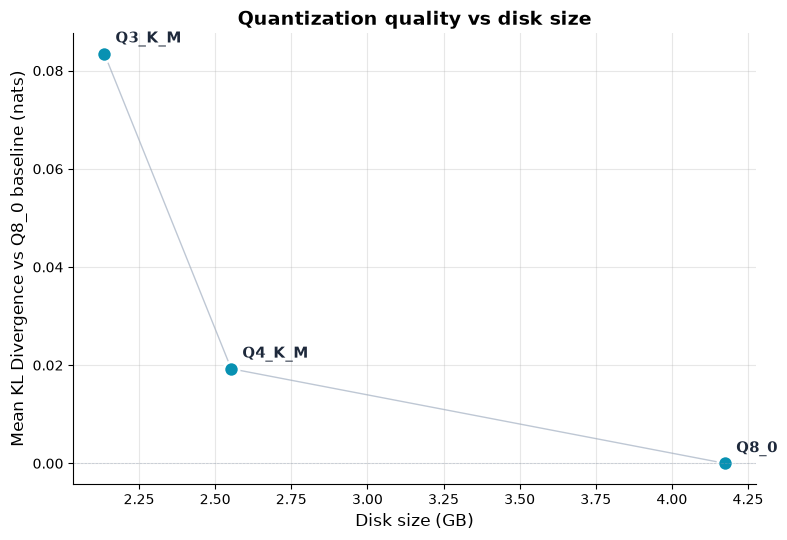

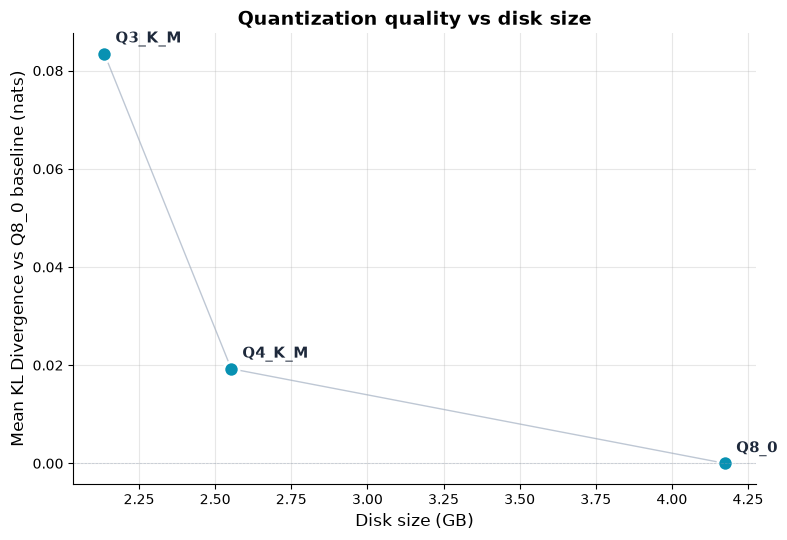

In [17]:
def plot_kld_vs_size(df: pd.DataFrame, title: str = 'Quantization quality vs disk size'):
    fig, ax = plt.subplots(figsize=(8, 5.5))
    sizes = df['size_gb'].values
    klds = df['mean_kld'].values
    order = np.argsort(sizes)
    ax.plot(sizes[order], klds[order], '-', color='#94A3B8',
            linewidth=1, alpha=0.6, zorder=1)
    ax.scatter(sizes, klds, s=120, c='#0891B2',
              edgecolor='white', linewidth=2, zorder=2)
    for _, row in df.iterrows():
        ax.annotate(row['variant'],
                    xy=(row['size_gb'], row['mean_kld']),
                    xytext=(8, 8), textcoords='offset points',
                    fontsize=11, fontweight='bold', color='#1E293B')
    ax.set_xlabel('Disk size (GB)', fontsize=12)
    ax.set_ylabel('Mean KL Divergence vs Q8_0 baseline (nats)', fontsize=12)
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.grid(True, alpha=0.3)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.axhline(y=0, color='#94A3B8', linestyle='--', linewidth=0.5, alpha=0.5)
    plt.tight_layout()
    plt.show()
    return fig

plot_kld_vs_size(df)

## 7. 관찰 — 곡선의 모양

위 plot에서 무엇이 보이는가?

- Q5_K_M의 KLD는 거의 0 — 5.7 bits/weight인데도 fp16과 구분이 어려움
- Q4_K_M까지도 KLD가 매우 작게 유지 — 그래서 "sweet spot"
- Q3_K_M부터 KLD가 눈에 띄게 증가 — 품질 저하 구간 진입

그런데 **Q3_K_M보다 더 낮은 비트**로 가면 어떻게 될까? 이론적으로는 KLD 곡선이 가파르게 치솟아야 함. 강의 교안에서 "Q2_K는 비상용"이라고 묘사됨. 직접 측정해봅시다.

## 🎯 다른 양자화 방식도 추가하려면 아래 내용을 참고해주세요

**아래 셀에서 `VARIANTS_EXTENDED` 리스트에 예를 들어 `'Q2_K'`를 추가**하고 다음 셀들을 차례로 실행하세요. 

그러면 자동으로:
1. Q2_K GGUF가 다운로드되고
2. KLD가 측정되고
3. plot에 새 데이터 포인트가 추가됩니다.

**관찰 포인트**:
- Q3_K_M에서 Q4_K_M으로의 KLD 변화량과,
- Q2_K에서 Q3_K_M으로의 KLD 변화량을 비교해보세요. **단순한 선형 증가가 아닙니다**.
- 본인이 A4000(16GB)에 배포한다면, 이 plot 위 어느 지점을 고를 것인가? (03번 프리셋에서 4B는 Q8_0, 7B는 Q4_K_M을 고른 이유와 연결해보세요)

In [18]:
# TODO: 아래 리스트에 'Q2_K'를 추가하세요
VARIANTS_EXTENDED = ['Q8_0', 'Q5_K_M', 'Q4_K_M', 'Q3_K_M']
#                                                            ↑ 여기에 추가

assert 'Q2_K' in VARIANTS_EXTENDED, 'TODO: Q2_K를 리스트에 추가하세요'

AssertionError: TODO: Q2_K를 리스트에 추가하세요

In [ ]:
# ✅ 참고 답안 (핵심)
VARIANTS_EXTENDED = ['Q8_0', 'Q5_K_M', 'Q4_K_M', 'Q3_K_M', 'Q2_K']  # 'Q2_K' 추가

In [ ]:
from huggingface_hub import snapshot_download

# 기존 결과에 없는 새 variant만 다운로드 + KLD 측정
new_variants = [v for v in VARIANTS_EXTENDED if v not in {r['variant'] for r in results}]
print(f'새로 측정할 variant: {new_variants}')

if new_variants:
    snapshot_download(
        repo_id=REPO,
        local_dir=MODEL_DIR,
        allow_patterns=[f'*{v}*' for v in new_variants],
    )
    files = sorted(glob.glob(f'{MODEL_DIR}/**/*.gguf', recursive=True))

    for variant in new_variants:
        path = find_path(variant)
        size_gb = os.path.getsize(path) / (1024**3)
        print(f'\n--- {variant} ({size_gb:.2f} GB) ---')

        start_server(path)
        quant_dists = collect_all_prompts()
        stop_server()

        klds_new = [kld(baseline_dists[i], quant_dists[i])
                    for i in range(len(EVAL_PROMPTS))]
        results.append({
            'variant': variant, 'size_gb': size_gb,
            'mean_kld': float(np.mean(klds_new)),
            'max_kld': float(np.max(klds_new)),
        })
        print(f'  mean KLD = {np.mean(klds_new):.6f}')

df_extended = pd.DataFrame(results).sort_values('size_gb').reset_index(drop=True)
df_extended

In [ ]:
plot_kld_vs_size(df_extended, title='Quantization quality vs disk size (Q2_K 포함)')

---

## 정리

방금 본 plot의 의미:

- **Q5_K_M ~ Q4_K_M 구간**은 KLD가 거의 평평 — 이 구간에서는 size가 작아져도 품질 거의 유지
- **Q3_K_M에서 곡선이 휘기 시작** — 품질 저하가 가시화
- **Q2_K는 절벽** — 그래서 강의에서 "비상용"이라고 한 것

이 plot이 **본인의 배포 환경에 맞는 quant 선택의 근거**입니다.  
다음 모델을 양자화 배포할 때는 "좋다더라" 대신 이렇게 측정하세요.

> 공용 서버를 껐다면 05번 실습 전에 터미널에서 `python local_server.py start 4b`로 다시 시작하세요.

### 참고: 이번 측정의 한계

- llama-server HTTP API로 top-128 확률만 수집한 **근사 KLD**입니다. 정밀 측정은 `llama-perplexity --kl-divergence`로.
- 같은 quant라도 calibration imatrix 사용 여부에 따라 KLD가 달라짐.
- 본인이 fine-tune한 모델은 base 모델과 outlier 분포가 다를 수 있어서 baseline KLD 곡선도 달라짐.

## ✅ 정리 & 스스로 점검

**양자화 선택 가이드 (A4000 16GB 기준)**

| 상황 | 추천 |
|---|---|
| VRAM 여유가 충분 (모델이 작음) | Q8_0 — 원본과 거의 동일 (03번 4B 프리셋) |
| 더 큰 모델을 올리고 싶음 | Q4_K_M — 품질 손실이 작은 균형점 (03번 7B 프리셋) |
| 도구 호출·JSON처럼 형식이 중요한 작업 | Q4_K_M 이상 권장 (Q3 이하는 인자 JSON이 깨지기 쉬움) |
| Q3 이하 | 다른 방법이 없을 때만 |

> 일반적으로 **"작은 모델의 고정밀"보다 "큰 모델의 Q4"가 더 나은 경우가 많습니다.** 03번에서 4B·7B 프리셋을 바꿔 가며 직접 비교해 보세요.

**스스로 점검**
1. 7B 모델을 Q8_0으로 올리면 VRAM이 얼마나 필요할까요? (00번 3절 공식 이용)
2. KL divergence가 0에 가깝다는 것은 실제 답변에 어떤 의미일까요?
